In [34]:
# IMPORT LIBRARIES 

import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler 
from sklearn.model_selection import train_test_split 
from sklearn.linear_model import LogisticRegression 
from sklearn.metrics import classification_report,accuracy_score 
from sklearn.preprocessing import StandardScaler 
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import os
from imblearn.over_sampling import SMOTE

import joblib

In [2]:
# ── Create a folder to store all visuals ─────────────────────
os.makedirs('visuals', exist_ok=True)

In [3]:
dd = pd.read_csv('diabetes_dataset.csv')
dd.head()

,year,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,smoking_history,bmi,hbA1c_level,blood_glucose_level,diabetes
0,2020,Female,32.0,Alabama,0,0,0,0,1,0,0,never,27.32,5.0,100,0
1,2015,Female,29.0,Alabama,0,1,0,0,0,0,0,never,19.95,5.0,90,0
2,2015,Male,18.0,Alabama,0,0,0,0,1,0,0,never,23.76,4.8,160,0
3,2015,Male,41.0,Alabama,0,0,1,0,0,0,0,never,27.32,4.0,159,0
4,2016,Female,52.0,Alabama,1,0,0,0,0,0,0,never,23.75,6.5,90,0


In [4]:
dd

,year,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,smoking_history,bmi,hbA1c_level,blood_glucose_level,diabetes
0,2020,Female,32.0,Alabama,0,0,0,0,1,0,0,never,27.32,5.0,100,0
1,2015,Female,29.0,Alabama,0,1,0,0,0,0,0,never,19.95,5.0,90,0
2,2015,Male,18.0,Alabama,0,0,0,0,1,0,0,never,23.76,4.8,160,0
3,2015,Male,41.0,Alabama,0,0,1,0,0,0,0,never,27.32,4.0,159,0
4,2016,Female,52.0,Alabama,1,0,0,0,0,0,0,never,23.75,6.5,90,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,2018,Female,33.0,Wyoming,0,0,0,0,1,0,0,never,21.21,6.5,90,0
99996,2016,Female,80.0,Wyoming,0,1,0,0,0,0,0,No Info,36.66,5.7,100,0
99997,2018,Male,46.0,Wyoming,0,1,0,0,0,0,0,ever,36.12,6.2,158,0
99998,2018,Female,51.0,Wyoming,1,0,0,0,0,0,0,not current,29.29,6.0,155,0


In [5]:
dd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 16 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   year                  100000 non-null  int64  
 1   gender                100000 non-null  object 
 2   age                   100000 non-null  float64
 3   location              100000 non-null  object 
 4   race:AfricanAmerican  100000 non-null  int64  
 5   race:Asian            100000 non-null  int64  
 6   race:Caucasian        100000 non-null  int64  
 7   race:Hispanic         100000 non-null  int64  
 8   race:Other            100000 non-null  int64  
 9   hypertension          100000 non-null  int64  
 10  heart_disease         100000 non-null  int64  
 11  smoking_history       100000 non-null  object 
 12  bmi                   100000 non-null  float64
 13  hbA1c_level           100000 non-null  float64
 14  blood_glucose_level   100000 non-null  int64  
 15  d

In [6]:
# scaling - year, age, bmi, blood_glucose_level, hbA1c_level
# label encoding - gender
# one hot encoding - smoking_history
# mapping 
# target encoding - location

Saved: visuals/class_distribution.png


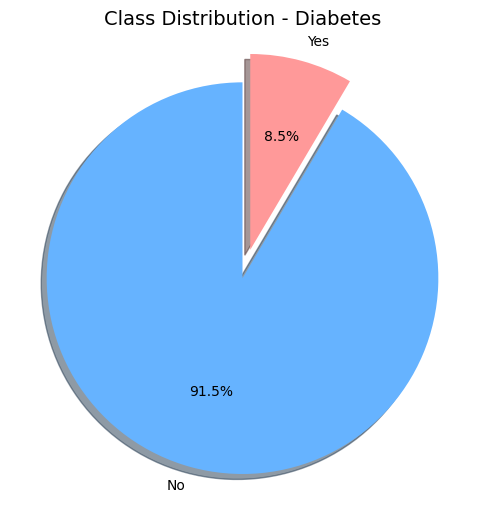

In [ ]:
r = dd['diabetes'].value_counts()

# Pie chart
plt.figure(figsize=(6, 6))
plt.pie(r, 
        explode=[0.05, 0.1], 
        labels=['No', 'Yes'],          # adjust if your labels are 0/1 → ['0', '1']
        autopct='%1.1f%%', 
        shadow=True, 
        startangle=90, 
        colors=['#66b3ff', '#ff9999'])

plt.title('Class Distribution - Diabetes', fontsize=14)
plt.axis('equal')  # makes it a perfect circle

# Save and show
plt.savefig('visuals/class_distribution.png', dpi=300, bbox_inches='tight')
print("Saved: visuals/class_distribution.png")
plt.show()

In [13]:
# Target Encoding for 'location'
# location survival rates from YOUR data:
location_diabetes = dd.groupby('location')['diabetes'].mean()

# Each location gets replaced by its diabetes rate
dd['location_encoded'] = dd['location'].map(location_diabetes)

In [14]:
# label encoding

le = LabelEncoder().fit_transform
dd["gender_Encoded"] = LabelEncoder().fit_transform(dd["gender"])

In [15]:
# one hot encoding for smoking_history

dd = pd.get_dummies(dd, columns=[ 'smoking_history'], drop_first=True)
                                  

bool_cols = dd.select_dtypes(include='bool').columns
dd[bool_cols] = dd[bool_cols].astype(int)

KeyError: "None of [Index(['smoking_history'], dtype='object')] are in the [columns]"

In [16]:
dd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 22 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   year                         100000 non-null  int64  
 1   gender                       100000 non-null  object 
 2   age                          100000 non-null  float64
 3   location                     100000 non-null  object 
 4   race:AfricanAmerican         100000 non-null  int64  
 5   race:Asian                   100000 non-null  int64  
 6   race:Caucasian               100000 non-null  int64  
 7   race:Hispanic                100000 non-null  int64  
 8   race:Other                   100000 non-null  int64  
 9   hypertension                 100000 non-null  int64  
 10  heart_disease                100000 non-null  int64  
 11  bmi                          100000 non-null  float64
 12  hbA1c_level                  100000 non-null  float64
 13  

In [12]:
dd

,year,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,...,hbA1c_level,blood_glucose_level,diabetes,location_encoded,gender_Encoded,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
0,2020,Female,32.0,Alabama,0,0,0,0,1,0,...,5.0,100,0,NaN,0,0,0,0,1,0
1,2015,Female,29.0,Alabama,0,1,0,0,0,0,...,5.0,90,0,NaN,0,0,0,0,1,0
2,2015,Male,18.0,Alabama,0,0,0,0,1,0,...,4.8,160,0,NaN,1,0,0,0,1,0
3,2015,Male,41.0,Alabama,0,0,1,0,0,0,...,4.0,159,0,NaN,1,0,0,0,1,0
4,2016,Female,52.0,Alabama,1,0,0,0,0,0,...,6.5,90,0,NaN,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,2018,Female,33.0,Wyoming,0,0,0,0,1,0,...,6.5,90,0,NaN,0,0,0,0,1,0
99996,2016,Female,80.0,Wyoming,0,1,0,0,0,0,...,5.7,100,0,NaN,0,0,0,0,0,0
99997,2018,Male,46.0,Wyoming,0,1,0,0,0,0,...,6.2,158,0,NaN,1,0,1,0,0,0
99998,2018,Female,51.0,Wyoming,1,0,0,0,0,0,...,6.0,155,0,NaN,0,0,0,0,0,1


In [ ]:
# scaling - year, age, bmi, blood_glucose_level, hbA1c_level

In [18]:
cd = columns_to_drop = ["location","gender"]
New_dd = dd.drop(columns=cd)

In [19]:
New_dd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   year                         100000 non-null  int64  
 1   age                          100000 non-null  float64
 2   race:AfricanAmerican         100000 non-null  int64  
 3   race:Asian                   100000 non-null  int64  
 4   race:Caucasian               100000 non-null  int64  
 5   race:Hispanic                100000 non-null  int64  
 6   race:Other                   100000 non-null  int64  
 7   hypertension                 100000 non-null  int64  
 8   heart_disease                100000 non-null  int64  
 9   bmi                          100000 non-null  float64
 10  hbA1c_level                  100000 non-null  float64
 11  blood_glucose_level          100000 non-null  int64  
 12  diabetes                     100000 non-null  int64  
 13  

In [77]:
features = ["age","hypertension","heart_disease","bmi","hbA1c_level","blood_glucose_level"]
output = ["diabetes"]

In [78]:
X = New_dd[features]
y = New_dd[output]

In [79]:
X_train, X_test,y_train, y_test =train_test_split(X,y,test_size = 0.2,random_state = 42, stratify = y)

In [80]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ADD THIS RIGHT AFTER
X_test.to_csv('test_set.csv', index=False)
y_test.to_csv('test_labels.csv', index=False)

print("Test set saved!")
print(f"Test set size: {len(X_test)} rows")

Test set saved!
Test set size: 20000 rows


In [81]:
# Load the test labels
test_labels = pd.read_csv('test_labels.csv')

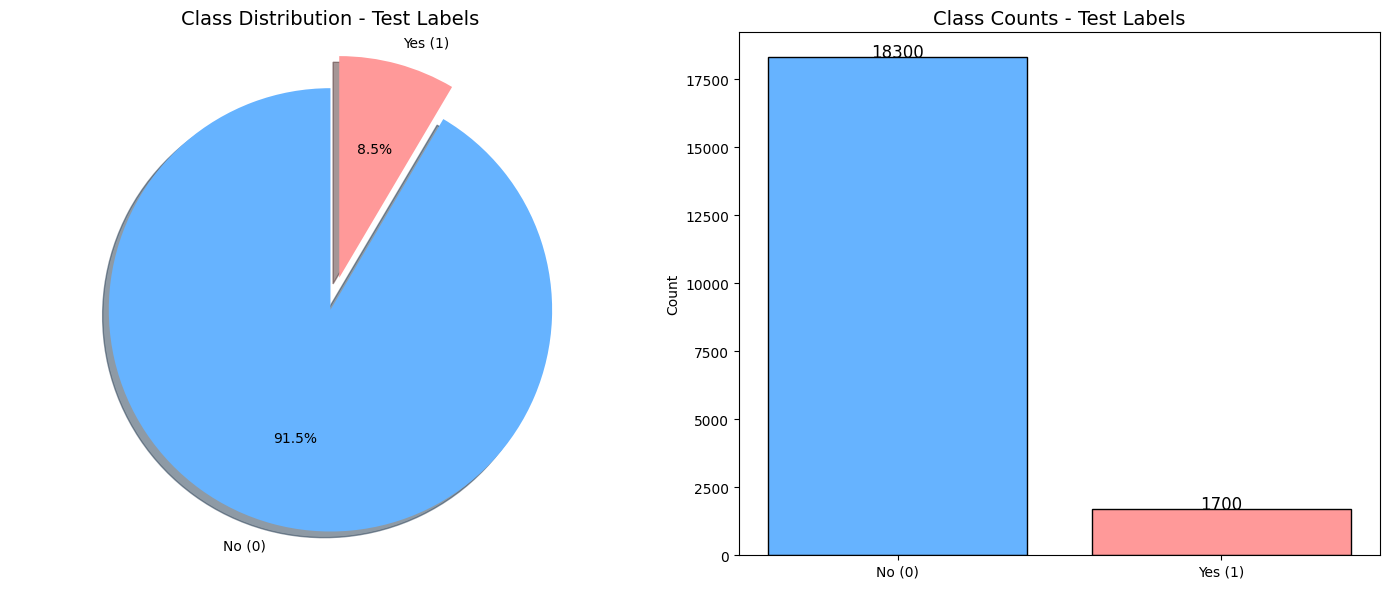


--- Test Label Summary ---
Total samples : 20000
No Diabetes (0): 18300 (91.5%)
Diabetes (1)   : 1700 (8.5%)
Imbalance ratio: 10.76:1


In [82]:
m = test_labels['diabetes'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- Pie Chart ---
axes[0].pie(m,
            explode=[0.05, 0.1],
            labels=['No (0)', 'Yes (1)'],
            autopct='%1.1f%%',
            shadow=True,
            startangle=90,
            colors=['#66b3ff', '#ff9999'])
axes[0].set_title('Class Distribution - Test Labels', fontsize=14)
axes[0].axis('equal')

# --- Bar Chart (bonus - easier to read exact counts) ---
bars = axes[1].bar(['No (0)', 'Yes (1)'], m, color=['#66b3ff', '#ff9999'], edgecolor='black')
axes[1].set_title('Class Counts - Test Labels', fontsize=14)
axes[1].set_ylabel('Count')
for bar in bars:
    axes[1].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 5,
                 str(bar.get_height()),
                 ha='center', fontsize=12)

plt.tight_layout()
plt.savefig('visuals/test_class_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

# Summary stats
print("\n--- Test Label Summary ---")
print(f"Total samples : {len(test_labels)}")
print(f"No Diabetes (0): {m[0]} ({m[0]/len(test_labels)*100:.1f}%)")
print(f"Diabetes (1)   : {m[1]} ({m[1]/len(test_labels)*100:.1f}%)")
print(f"Imbalance ratio: {m[0]/m[1]:.2f}:1")

In [83]:
#STANDARDIZATION
# Scaler
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [84]:
#DEFINE A MODEL
#Start with Logistic Regression

model_LR = LogisticRegression(max_iter=1000, class_weight = "balanced")
model_LR.fit(X_train,y_train)

c:\Users\akeem\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [85]:
y_pred = model_LR.predict(X_test)

In [86]:
#print accuracy score
print("accuracy_score:")

print(accuracy_score(y_test,y_pred))

accuracy_score:
0.8872


In [88]:
print("classification report:")

print(classification_report(y_test,y_pred))

classification report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     18300
           1       0.42      0.87      0.57      1700

    accuracy                           0.89     20000
   macro avg       0.70      0.88      0.75     20000
weighted avg       0.94      0.89      0.90     20000



In [89]:
# BEFORE SMOTE - Fixed
print("=== BEFORE SMOTE ===")
before = pd.Series(y_train.values.ravel()).value_counts().sort_index()

for label, count in before.items():
    pct = count / len(y_train) * 100
    print(f"  Class {label}: {count:>6,}  ({pct:.1f}%)")

print(f"  Total  : {len(y_train):>6,}")

=== BEFORE SMOTE ===
  Class 0: 73,200  (91.5%)
  Class 1:  6,800  (8.5%)
  Total  : 80,000


In [90]:
#SMOTE
smote = SMOTE(random_state = 42)

X_train_resampled, y_train_resampled = smote.fit_resample(X_train,y_train)

In [91]:
# AFTER SMOTE
print("=== AFTER SMOTE ===")
after = pd.Series(y_train_resampled.values.ravel()).value_counts().sort_index()

for label, count in after.items():
    pct = count / len(y_train_resampled) * 100
    print(f"  Class {label}: {count:>6,}  ({pct:.1f}%)")

print(f"  Total  : {len(y_train_resampled):>6,}")

=== AFTER SMOTE ===
  Class 0: 73,200  (50.0%)
  Class 1: 73,200  (50.0%)
  Total  : 146,400


In [92]:
#DEFINE A MODEL
#Start with Logistic Regression

model_LR2 = LogisticRegression(max_iter=1000)
model_LR2.fit(X_train_resampled,y_train_resampled)

c:\Users\akeem\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [93]:
y_pred2 = model_LR2.predict(X_test)

In [95]:
print("classification report:")

print(classification_report(y_test,y_pred2))

classification report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     18300
           1       0.42      0.87      0.57      1700

    accuracy                           0.89     20000
   macro avg       0.70      0.88      0.75     20000
weighted avg       0.94      0.89      0.90     20000



In [96]:
#RandomForestClassifier
model_rfc = RandomForestClassifier(n_estimators=100, random_state = 42)

model_rfc.fit(X_train_resampled,y_train_resampled)

c:\Users\akeem\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [97]:
y_pred_rfc = model_rfc.predict(X_test)

In [98]:
print("classification report:")

print(classification_report(y_test,y_pred_rfc))

classification report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98     18300
           1       0.79      0.74      0.76      1700

    accuracy                           0.96     20000
   macro avg       0.88      0.86      0.87     20000
weighted avg       0.96      0.96      0.96     20000



In [99]:
model_XGB = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    eval_metric='logloss'
  
)


model_XGB.fit(X_train_resampled, y_train_resampled)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


In [100]:
y_pred_xgb = model_XGB.predict(X_test)

In [101]:
print("classification report:")

print(classification_report(y_test,y_pred_xgb))

classification report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98     18300
           1       0.87      0.73      0.79      1700

    accuracy                           0.97     20000
   macro avg       0.92      0.86      0.89     20000
weighted avg       0.97      0.97      0.97     20000



C:\Users\akeem\AppData\Local\Temp\ipykernel_26012\3602683877.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values,


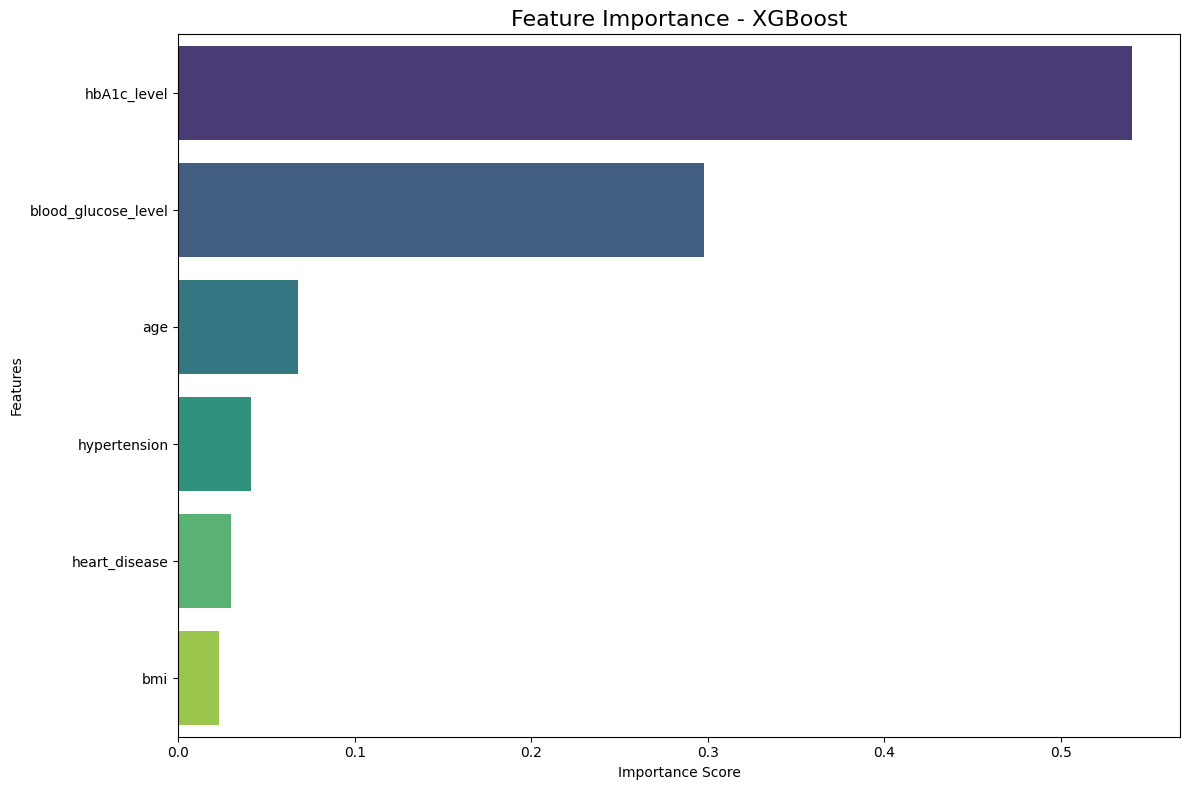

Saved: visuals/feature_importance_xgb.png

Top 10 Most Important Features (XGBoost):
hbA1c_level            0.540364
blood_glucose_level    0.298066
age                    0.067675
hypertension           0.040979
heart_disease          0.029686
bmi                    0.023230
dtype: float32


In [102]:
# ── Feature Importance Chart - XGBoost ───────────────────────

# Get feature importances from XGBoost
importances = pd.Series(model_XGB.feature_importances_, 
                        index=features)   # 'features' should be your list of column names

importances = importances.sort_values(ascending=False)

# Plot
plt.figure(figsize=(12, 8))
sns.barplot(x=importances.values, 
            y=importances.index, 
            palette='viridis')

plt.title('Feature Importance - XGBoost', fontsize=16)
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()

# Save the plot
plt.savefig('visuals/feature_importance_xgb.png', dpi=300, bbox_inches='tight')
plt.show()

print("Saved: visuals/feature_importance_xgb.png")

# Optional: Print the top features nicely
print("\nTop 10 Most Important Features (XGBoost):")
print(importances.head(10))

In [105]:
# Save the model and scaler
joblib.dump(model_XGB, 'diabetes_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

print("Model saved successfully!")

Model saved successfully!
